In [ ]:
# logistic regression with gradient descent 
# binary classification 
# model: z = wx + b and sigmoid(z) = 1 / (1 + exp(-z)) > 0.5 -> class 1, else class 0
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)

In [ ]:
# creates a dataset of 200 points in 2D space, with two classes 
m = 200
n_x = 2

m_half = m // 2
X0 = np.random.randn(m_half, n_x) + np.array([-2.0, -2.0])
X1 = np.random.randn(m - m_half, n_x) + np.array([2.0, 2.0])

X = np.vstack([X0, X1]).T                                  # (n_x, m)
Y = np.hstack([np.zeros(m_half), np.ones(m - m_half)]).reshape(1, m)  # (1, m)

perm = np.random.permutation(m)
X, Y = X[:, perm], Y[:, perm]

X.shape, Y.shape

((2, 200), (1, 200))

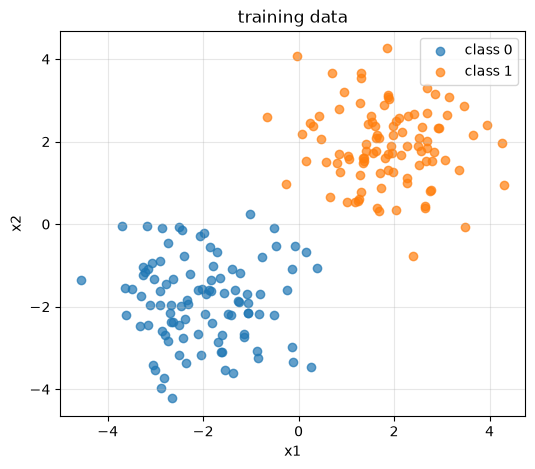

In [ ]:
# plots the training data
y = Y.ravel() # flatten Y to a 1D array for plotting

plt.figure(figsize=(6, 5))
plt.scatter(X[0, y == 0], X[1, y == 0], c="tab:blue", alpha=0.7, label="class 0")
plt.scatter(X[0, y == 1], X[1, y == 1], c="tab:orange", alpha=0.7, label="class 1")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("training data")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
def sigmoid(z): 
    return np.where(z >= 0, 1.0 / (1.0 + np.exp(-z)), np.exp(z) / (1.0 + np.exp(z)))

In [ ]:
def train(X, Y, alpha=0.1, num_iterations=500):
    n_x, m = X.shape # defines number of features and number of samples
    w = np.zeros((n_x, 1)) # initilize weights to zeros
    b = 0.0 # initialize bias to zero
    costs = []
    W_hist = []
    b_hist = []

    for i in range(num_iterations):  # loop over the number of iterations for gradient descent
        Z = np.dot(w.T, X) + b 
        A = sigmoid(Z)
        J = -(1/m) * np.sum(Y * np.log(A + 1e-8) + (1 - Y) * np.log(1 - A + 1e-8)) # compute cost function

        # compute derivatives 
        dZ = A - Y  
        dw = (1/m) * np.dot(X, dZ.T)
        db = (1/m) * np.sum(dZ)

        # update parameters based on the derivatives and learning rate
        w = w - alpha * dw
        b = b - alpha * db

        costs.append(J)
        W_hist.append(w.copy())     # snapshot of weights after this step
        b_hist.append(b)

    return w, b, costs, W_hist, b_hist

In [ ]:
w, b, costs, W_hist, b_hist = train(X, Y, alpha=0.1, num_iterations=500) 

preds = (sigmoid(np.dot(w.T, X) + b) >= 0.5).astype(int) # make predictions based on the learned weights and bias
acc = np.mean(preds == Y) # compute accuracy of the model

print("w =", w.ravel()) 
print("b =", b)
print("final cost =", costs[-1])
print("accuracy =", acc)

w = [1.73769516 1.82672466]
b = -0.13241601437355288
final cost = 0.014491298472127535
accuracy = 1.0


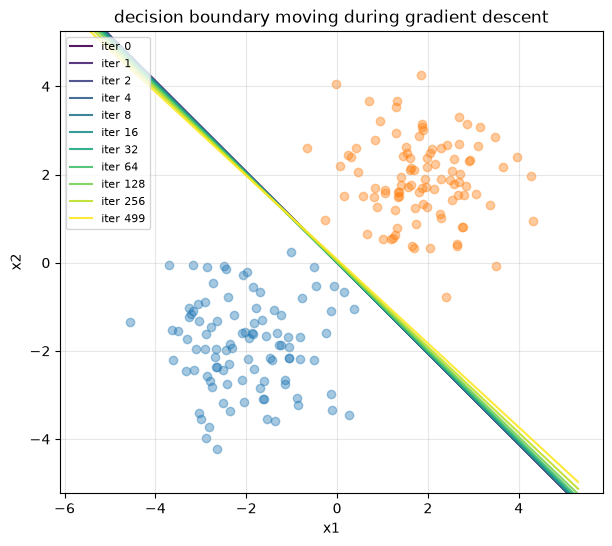

In [ ]:
x1 = np.linspace(X[0].min() - 1, X[0].max() + 1, 100) # create a range of x1 values for plotting decision boundaries
steps = [0, 1, 2, 4, 8, 16, 32, 64, 128, 256, len(costs) - 1] # define the steps at which to plot the decision boundary
colors = plt.cm.viridis(np.linspace(0, 1, len(steps))) # define colors for each step

plt.figure(figsize=(7, 6))
plt.scatter(X[0, y == 0], X[1, y == 0], c="tab:blue", alpha=0.4)
plt.scatter(X[0, y == 1], X[1, y == 1], c="tab:orange", alpha=0.4)

# plot decision boundaries at different steps of gradient descent
for c, it in zip(colors, steps):
    w_it = W_hist[it] 
    b_it = b_hist[it]
    if abs(w_it[1, 0]) < 1e-8:
        continue
    x2 = -(w_it[0, 0] * x1 + b_it) / w_it[1, 0]
    plt.plot(x1, x2, color=c, alpha=0.9, label=f"iter {it}")

plt.ylim(X[1].min() - 1, X[1].max() + 1)
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("decision boundary moving during gradient descent")
plt.legend(fontsize=8, loc="upper left"); plt.grid(alpha=0.3)
plt.show()

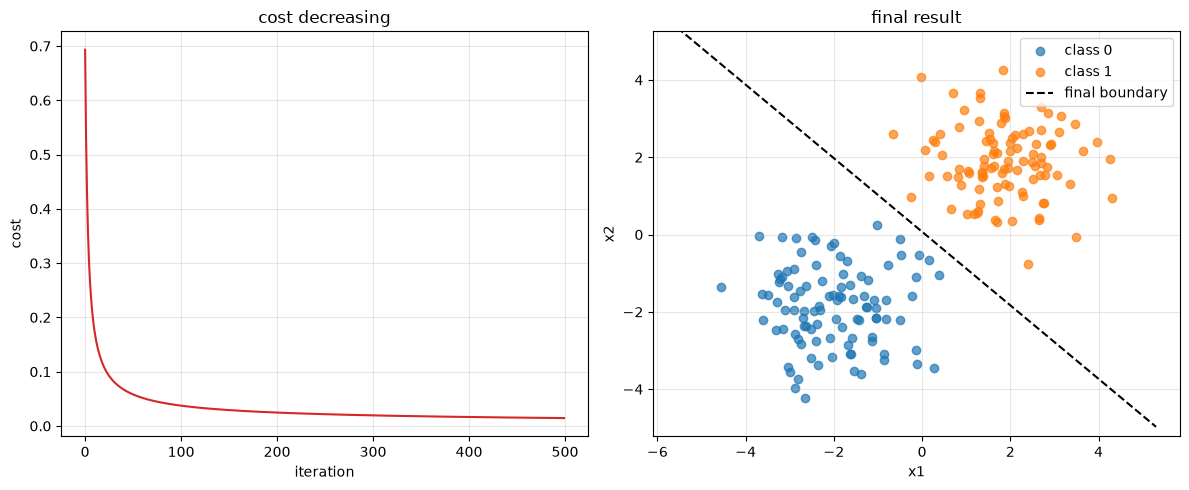

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(costs, color="tab:red")
ax1.set_xlabel("iteration"); ax1.set_ylabel("cost"); ax1.set_title("cost decreasing")
ax1.grid(alpha=0.3)

ax2.scatter(X[0, y == 0], X[1, y == 0], c="tab:blue", alpha=0.7, label="class 0")
ax2.scatter(X[0, y == 1], X[1, y == 1], c="tab:orange", alpha=0.7, label="class 1")
x2_final = -(w[0, 0] * x1 + b) / w[1, 0]
ax2.plot(x1, x2_final, "k--", label="final boundary")
ax2.set_ylim(X[1].min() - 1, X[1].max() + 1)
ax2.set_xlabel("x1"); ax2.set_ylabel("x2"); ax2.set_title("final result")
ax2.legend(); ax2.grid(alpha=0.3)

plt.tight_layout(); plt.show()

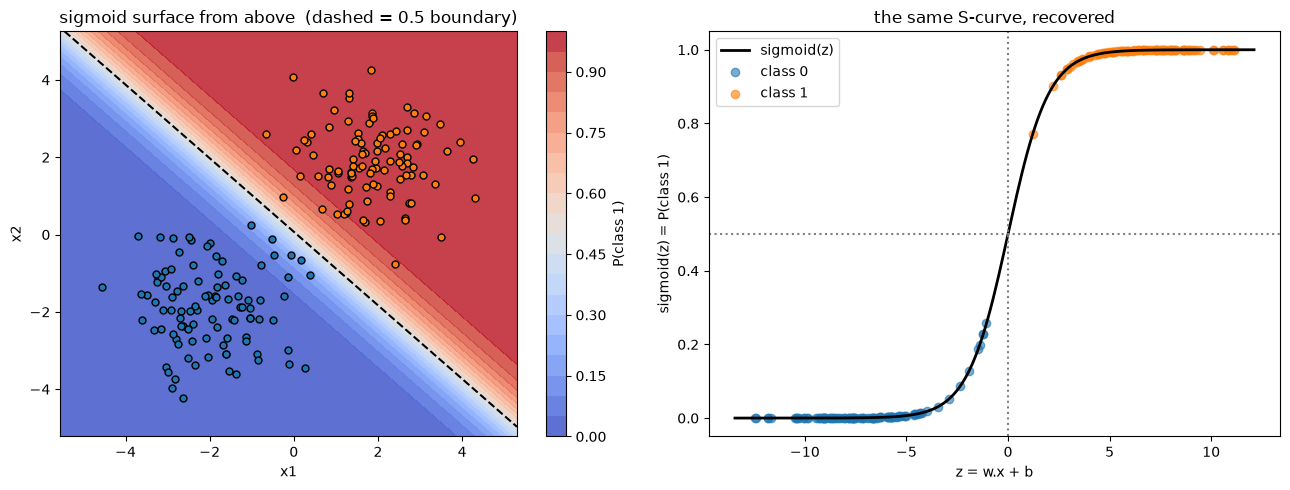

In [ ]:
# plot the sigmoid surface and the S-curve 
xx1, xx2 = np.meshgrid(np.linspace(X[0].min() - 1, X[0].max() + 1, 200),
                       np.linspace(X[1].min() - 1, X[1].max() + 1, 200)) 
grid = np.vstack([xx1.ravel(), xx2.ravel()]) 
probs_grid = sigmoid(np.dot(w.T, grid) + b).reshape(xx1.shape) # compute probabilities for each point in the grid

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5)) 

cf = ax1.contourf(xx1, xx2, probs_grid, levels=20, cmap="coolwarm", alpha=0.85) # plot filled contour of probabilities
ax1.contour(xx1, xx2, probs_grid, levels=[0.5], colors="k", linestyles="--") # plot decision boundary where probability = 0.5
ax1.scatter(X[0, y == 0], X[1, y == 0], c="tab:blue", edgecolor="k", s=25) # plot class 0 points
ax1.scatter(X[0, y == 1], X[1, y == 1], c="tab:orange", edgecolor="k", s=25) # plot class 1 points
fig.colorbar(cf, ax=ax1, label="P(class 1)") # add colorbar to indicate probability values
ax1.set_xlabel("x1"); ax1.set_ylabel("x2") 
ax1.set_title("sigmoid surface from above  (dashed = 0.5 boundary)")

z_vals = (np.dot(w.T, X) + b).ravel() # compute z values for each training point
z_line = np.linspace(z_vals.min() - 1, z_vals.max() + 1, 200) # create a range of z values for plotting the sigmoid curve
ax2.plot(z_line, sigmoid(z_line), "k-", lw=2, label="sigmoid(z)") # plot the sigmoid curve
ax2.scatter(z_vals[y == 0], sigmoid(z_vals[y == 0]), c="tab:blue", alpha=0.6, label="class 0")
ax2.scatter(z_vals[y == 1], sigmoid(z_vals[y == 1]), c="tab:orange", alpha=0.6, label="class 1")
ax2.axhline(0.5, color="gray", ls=":"); ax2.axvline(0, color="gray", ls=":")
ax2.set_xlabel("z = w.x + b"); ax2.set_ylabel("sigmoid(z) = P(class 1)")
ax2.set_title("the same S-curve, recovered")
ax2.legend()

plt.tight_layout(); plt.show()

In [ ]:
def predict(X_new, w, b):
    A = sigmoid(np.dot(w.T, X_new) + b)      # probabilities, (1, k)
    return A.ravel(), (A.ravel() >= 0.5).astype(int)

X_new = np.array([[-3.0, 3.0, 0.0, -1.0, 2.0],
                  [-2.0, 2.5, 0.0,  1.5, -1.0]])   # (n_x, k): each column is a new point

probs, labels = predict(X_new, w, b)

for i in range(X_new.shape[1]):
    p1, p2 = X_new[0, i], X_new[1, i]
    print(f"point ({p1:5.1f}, {p2:5.1f})  ->  P(class 1) = {probs[i]:.3f}  ->  class {labels[i]}")
    

point ( -3.0,  -2.0)  ->  P(class 1) = 0.000  ->  class 0
point (  3.0,   2.5)  ->  P(class 1) = 1.000  ->  class 1
point (  0.0,   0.0)  ->  P(class 1) = 0.467  ->  class 0
point ( -1.0,   1.5)  ->  P(class 1) = 0.705  ->  class 1
point (  2.0,  -1.0)  ->  P(class 1) = 0.820  ->  class 1


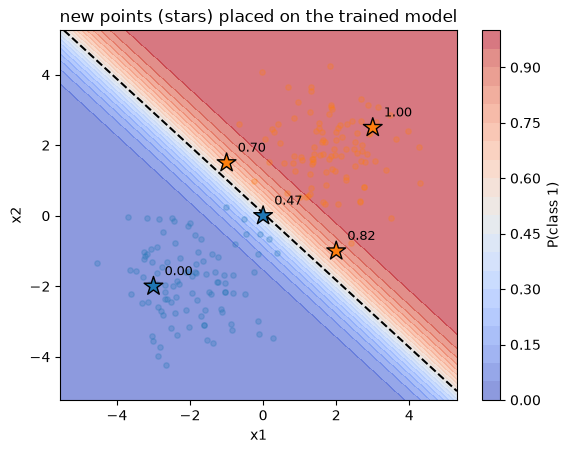

In [12]:
cf = plt.contourf(xx1, xx2, probs_grid, levels=20, cmap="coolwarm", alpha=0.6)
plt.contour(xx1, xx2, probs_grid, levels=[0.5], colors="k", linestyles="--")
plt.scatter(X[0, y == 0], X[1, y == 0], c="tab:blue", alpha=0.25, s=15)
plt.scatter(X[0, y == 1], X[1, y == 1], c="tab:orange", alpha=0.25, s=15)

new_colors = ["tab:orange" if l == 1 else "tab:blue" for l in labels]
plt.scatter(X_new[0], X_new[1], c=new_colors, edgecolor="k", s=200, marker="*", zorder=5)
for i in range(X_new.shape[1]):
    plt.annotate(f"{probs[i]:.2f}", (X_new[0, i], X_new[1, i]),
                 textcoords="offset points", xytext=(8, 8), fontsize=9)

plt.colorbar(cf, label="P(class 1)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("new points (stars) placed on the trained model")
plt.show()